<a href="https://colab.research.google.com/github/Lakshitha-Kavinda/cnn/blob/main/220316V_a02.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Name:** Kavinda L.G.L.  
**Index number:** 220316V  
**GitHub:** https://github.com/Lakshitha-Kavinda/cnn.git <br>
**Google colab link:** https://colab.research.google.com/drive/1Sg1uWKpscjeOHpOWMwUFPNT6cbEsFe6v?usp=sharing

**AI tool acknowledgment:** I have used Claude to help with coding.

In [ ]:
# from google.colab import drive
# drive.mount('/content/drive')
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Setup

In [ ]:
import os, random, time
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision
import matplotlib.pyplot as plt

SEED = 42
def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
set_seed()

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('torch', torch.__version__, '| device:', device)
if device.type == 'cuda':
    print(torch.cuda.get_device_name(0))

torch 2.11.0+cu130 | device: cuda
Tesla T4


### CIFAR-10: 45k train / 5k val, per-channel normalization with training statistics

In [ ]:
DRIVE_DIR = '/content/drive/MyDrive/EN4554_A02'
DATA_ROOT = f'{DRIVE_DIR}/data'
os.makedirs(DATA_ROOT, exist_ok=True)
os.makedirs(f'{DRIVE_DIR}/results', exist_ok=True)

CLASSES = ['airplane','automobile','bird','cat','deer','dog','frog','horse','ship','truck']

full = torchvision.datasets.CIFAR10(root=DATA_ROOT, train=True, download=True)
X_all = torch.from_numpy(full.data).permute(0, 3, 1, 2).float() / 255.0
y_all = torch.tensor(full.targets)

# fixed split, saved to Drive so it never changes between sessions
perm_path = f'{DRIVE_DIR}/split_perm.pt'
if os.path.exists(perm_path):
    perm = torch.load(perm_path)
else:
    g = torch.Generator().manual_seed(SEED)
    perm = torch.randperm(len(X_all), generator=g)
    torch.save(perm, perm_path)
tr_idx, va_idx = perm[:45000], perm[45000:]

# per-channel statistics from the TRAINING split only
MEAN = X_all[tr_idx].mean(dim=(0, 2, 3), keepdim=True)
STD  = X_all[tr_idx].std(dim=(0, 2, 3), keepdim=True)
normalize = lambda x: (x - MEAN) / STD

X_train, y_train = normalize(X_all[tr_idx]).to(device), y_all[tr_idx].to(device)
X_val,   y_val   = normalize(X_all[va_idx]).to(device), y_all[va_idx].to(device)

def load_test():
    """Task 4 ONLY. Call once, on the final model."""
    t = torchvision.datasets.CIFAR10(root=DATA_ROOT, train=False, download=True)
    X = torch.from_numpy(t.data).permute(0, 3, 1, 2).float() / 255.0
    return normalize(X).to(device), torch.tensor(t.targets).to(device)

print('train', tuple(X_train.shape), '| val', tuple(X_val.shape))
print('mean', MEAN.flatten().tolist(), '\nstd ', STD.flatten().tolist())

train (45000, 3, 32, 32) | val (5000, 3, 32, 32)
mean [0.49165481328964233, 0.4823332130908966, 0.4466792047023773] 
std  [0.24708116054534912, 0.2435086965560913, 0.2615806758403778]


In [ ]:
required = ['X_train', 'y_train', 'X_val', 'y_val', 'device', 'set_seed', 'SEED', 'DRIVE_DIR']
missing = [v for v in required if v not in globals()]
if missing:
    raise RuntimeError(f'Run the setup cells first (imports/seeds, GitHub, Google Drive data cell). Missing: {missing}')

os.makedirs(f'{DRIVE_DIR}/results', exist_ok=True)
os.makedirs(f'{DRIVE_DIR}/figures', exist_ok=True)

def savefig(name):
    # save to Drive (permanent) and, if the repo is cloned, to the repo's figures/ folder (for git)
    dirs = [f'{DRIVE_DIR}/figures']
    if 'REPO_DIR' in globals():
        dirs.append(f'{REPO_DIR}/figures')
    for d in dirs:
        os.makedirs(d, exist_ok=True)
        plt.savefig(f'{d}/{name}', dpi=150, bbox_inches='tight')

def result_path(name): return f'{DRIVE_DIR}/results/{name}.pt'
def result_exists(name): return os.path.exists(result_path(name))
def save_result(name, obj): torch.save(obj, result_path(name))
def load_result(name): return torch.load(result_path(name), weights_only=False)

print('device:', device, '| train', tuple(X_train.shape), '| val', tuple(X_val.shape))
print('Drive folder:', DRIVE_DIR)
print('Saved results so far:', sorted(os.listdir(f'{DRIVE_DIR}/results')))

device: cuda | train (45000, 3, 32, 32) | val (5000, 3, 32, 32)
Drive folder: /content/drive/MyDrive/EN4554_A02
Saved results so far: []


## Task 01

### 1) (a) Implement Linear, ReLU, and softmax cross-entropy with explicit forward/backward (no autograd), and assemble an MLP


In [ ]:
class Linear:
    def __init__(self, n_in, n_out, init='kaiming', dtype=torch.float32, device='cpu'):
        if init == 'kaiming':   std = (2.0 / n_in) ** 0.5            # He init (for ReLU)
        elif init == 'xavier':  std = (2.0 / (n_in + n_out)) ** 0.5  # Glorot init
        else: raise ValueError(init)
        self.W = torch.randn(n_in, n_out, dtype=dtype, device=device) * std
        self.b = torch.zeros(n_out, dtype=dtype, device=device)
        self.dW = torch.zeros_like(self.W)
        self.db = torch.zeros_like(self.b)

    def forward(self, x):
        self.x = x
        return x @ self.W + self.b

    def backward(self, dout):
        self.dW = self.x.T @ dout          # (in, N) @ (N, out)
        self.db = dout.sum(dim=0)
        return dout @ self.W.T             # gradient w.r.t. the input

    def step(self, lr):                    # plain SGD update
        self.W -= lr * self.dW
        self.b -= lr * self.db


class ReLU:
    def forward(self, x):
        self.mask = (x > 0)
        return x * self.mask

    def backward(self, dout):
        return dout * self.mask


class Sigmoid:
    def forward(self, x):
        self.y = 1.0 / (1.0 + torch.exp(-x))
        return self.y

    def backward(self, dout):
        return dout * self.y * (1.0 - self.y)


class SoftmaxCrossEntropy:
    def forward(self, logits, y):
        z = logits - logits.max(dim=1, keepdim=True).values            # numerical stability
        logp = z - torch.logsumexp(z, dim=1, keepdim=True)
        self.p = logp.exp()
        self.y = y
        return -logp[torch.arange(len(y), device=y.device), y].mean()

    def backward(self):
        g = self.p.clone()
        g[torch.arange(len(self.y), device=self.y.device), self.y] -= 1.0
        return g / len(self.y)


class MLP:
    def __init__(self, sizes, act='relu', init='kaiming', dtype=torch.float32, device='cpu'):
        self.layers = []
        for i in range(len(sizes) - 1):
            self.layers.append(Linear(sizes[i], sizes[i + 1], init, dtype, device))
            if i < len(sizes) - 2:                                      # no activation after the last layer
                self.layers.append(ReLU() if act == 'relu' else Sigmoid())
        self.loss_fn = SoftmaxCrossEntropy()

    def forward(self, x):
        for layer in self.layers:
            x = layer.forward(x)
        return x

    def loss(self, x, y):
        return self.loss_fn.forward(self.forward(x), y)

    def backward(self):
        g = self.loss_fn.backward()
        for layer in reversed(self.layers):
            g = layer.backward(g)

    def linears(self):
        return [l for l in self.layers if isinstance(l, Linear)]

    def step(self, lr):
        for l in self.linears():
            l.step(lr)

# quick shape / sanity test
_net = MLP([3072, 512, 256, 10], device=device)
_l = _net.loss(X_train[:64].flatten(1), y_train[:64]); _net.backward()
print('loss at init:', round(_l.item(), 3), '(about ln(10) = 2.303 for small logits)')
print('grad shapes :', [tuple(l.dW.shape) for l in _net.linears()])

loss at init: 2.975 (about ln(10) = 2.303 for small logits)
grad shapes : [(3072, 512), (512, 256), (256, 10)]


### 1) (b) Verify your gradients against autograd and against centred finite differences; report the relative errors. Use torch.allclose to check whether the gradients match

In [ ]:
def rel_err(a, b):
    return ((a - b).norm() / (a.norm() + b.norm() + 1e-12)).item()

def ref_forward(ps, x, act):
    # same network written with ordinary autograd ops
    h, n = x, len(ps) // 2
    for i in range(n):
        h = h @ ps[2 * i] + ps[2 * i + 1]
        if i < n - 1:
            h = F.relu(h) if act == 'relu' else torch.sigmoid(h)
    return h

def grad_check(act, h=1e-5, n_probe=10, seed=0):
    torch.manual_seed(seed)
    n_in, hid, n_cls, B = 20, 16, 10, 8
    net = MLP([n_in, hid, hid, n_cls], act=act, dtype=torch.float64)       # cpu, float64
    for l in net.linears():
        l.b = torch.randn_like(l.b) * 0.1                                  # non-zero biases, so db is tested properly
    xb = torch.randn(B, n_in, dtype=torch.float64)
    yb = torch.randint(0, n_cls, (B,))

    # manual
    loss_manual = net.loss(xb, yb); net.backward()
    manual = []
    for l in net.linears(): manual += [l.dW.clone(), l.db.clone()]
    names = [f'{k}{i + 1}' for i in range(len(net.linears())) for k in ('W', 'b')]

    # autograd
    ps = []
    for l in net.linears(): ps += [l.W.clone().requires_grad_(True), l.b.clone().requires_grad_(True)]
    loss_ag = F.cross_entropy(ref_forward(ps, xb, act), yb)
    loss_ag.backward()
    auto = [p.grad for p in ps]

    # centred finite differences (perturb the network's own parameters in place)
    params = []
    for l in net.linears(): params += [l.W, l.b]
    g = torch.Generator().manual_seed(seed)
    rows = []
    for name, p, gm, ga in zip(names, params, manual, auto):
        flat = p.view(-1)
        idx = torch.randperm(flat.numel(), generator=g)[:n_probe]
        worst = 0.0
        for i in idx.tolist():
            orig = flat[i].item()
            flat[i] = orig + h; lp = net.loss(xb, yb).item()
            flat[i] = orig - h; lm = net.loss(xb, yb).item()
            flat[i] = orig
            num, ana = (lp - lm) / (2 * h), gm.view(-1)[i].item()
            worst = max(worst, abs(num - ana) / (abs(num) + abs(ana) + 1e-12))
        rows.append((name, rel_err(gm, ga), torch.allclose(gm, ga, rtol=1e-7, atol=1e-10), worst))
    return abs(loss_manual.item() - loss_ag.item()), rows

check_results = {}
for act in ['relu']:
    dloss, rows = grad_check(act)
    check_results[act] = {'loss_diff': dloss, 'rows': rows}
    print(f'\n=== {act.upper()} MLP  |  |loss_manual - loss_autograd| = {dloss:.2e} ===')
    print(f'{"param":6s} {"rel.err vs autograd":>20s} {"allclose":>9s} {"max rel.err vs finite-diff":>28s}')
    for name, e_ag, ok, e_fd in rows:
        print(f'{name:6s} {e_ag:20.2e} {str(ok):>9s} {e_fd:28.2e}')
save_result('task1b_gradcheck', check_results)     # kept on Drive for the report


=== RELU MLP  |  |loss_manual - loss_autograd| = 0.00e+00 ===
param   rel.err vs autograd  allclose   max rel.err vs finite-diff
W1                 5.26e-17      True                     1.69e-09
b1                 4.22e-17      True                     8.73e-10
W2                 3.39e-17      True                     1.62e-08
b2                 9.49e-17      True                     2.63e-10
W3                 3.17e-17      True                     1.81e-10
b3                 5.21e-17      True                     4.58e-10


### Interpretation
The gradients from 1) (a) calculated without using autograd resulted relative errors of about 1e-16(max rel.err = 9.49e-17) for RELU. The centred finite differences resulted max relative error of 1.62e-08. Also these returned true for gradient match check using torch.allclose.

### 1) (c) Train it with SGD on flattened CIFAR-10 images; plot the loss and report validation accuracy.

In [ ]:
def mb_iter(X, y, bs, seed):
    g = torch.Generator().manual_seed(seed)
    idx = torch.randperm(len(X), generator=g).to(X.device)
    for i in range(0, len(X), bs):
        j = idx[i:i + bs]
        yield X[j], y[j]

def evaluate(net, X, y, bs=1000):
    tot, correct = 0.0, 0
    for i in range(0, len(X), bs):
        xb, yb = X[i:i + bs], y[i:i + bs]
        logits = net.forward(xb)
        tot += net.loss_fn.forward(logits, yb).item() * len(xb)
        correct += (logits.argmax(1) == yb).sum().item()
    return tot / len(X), correct / len(X)

def train_mlp(sizes, lr=0.05, epochs=20, bs=128, seed=42):
    set_seed(seed)
    net = MLP(sizes, act='relu', init='kaiming', device=device)
    Xtr, Xva = X_train.flatten(1), X_val.flatten(1)
    hist = {'iter_loss': [], 'train_loss': [], 'val_loss': [], 'val_acc': []}
    t0 = time.time()
    for ep in range(epochs):
        batch_losses = []
        for xb, yb in mb_iter(Xtr, y_train, bs, seed * 1000 + ep):
            loss = net.loss(xb, yb)
            net.backward()
            net.step(lr)
            batch_losses.append(loss.item())
        hist['iter_loss'] += batch_losses
        hist['train_loss'].append(float(np.mean(batch_losses)))
        vl, va = evaluate(net, Xva, y_val)
        hist['val_loss'].append(vl); hist['val_acc'].append(va)
        print(f'epoch {ep + 1:2d} | train loss {hist["train_loss"][-1]:.4f} | val loss {vl:.4f} | val acc {va:.4f}')
    print(f'done in {time.time() - t0:.0f}s')
    return net, hist

SIZES_C = [3072, 512, 256, 10]
RETRAIN = False        # set True to force retraining even if a saved result exists on Drive

if result_exists('task1c') and not RETRAIN:
    ck = load_result('task1c')
    hist_c = ck['hist']
    net_c = MLP(SIZES_C, act='relu', init='kaiming', device=device)
    for l, (W, b) in zip(net_c.linears(), ck['weights']):
        l.W, l.b = W.to(device), b.to(device)
    print('Loaded saved Task 1(c) result from Drive (no retraining). Set RETRAIN = True to train again.')
    print('Sanity check, val acc of the loaded network: %.4f' % evaluate(net_c, X_val.flatten(1), y_val)[1])
else:
    net_c, hist_c = train_mlp(SIZES_C)
    save_result('task1c', {'hist': hist_c, 'weights': [(l.W.cpu(), l.b.cpu()) for l in net_c.linears()]})
    print('Saved Task 1(c) result to Drive.')

epoch  1 | train loss 1.6931 | val loss 1.5394 | val acc 0.4652
epoch  2 | train loss 1.4140 | val loss 1.5013 | val acc 0.4814
epoch  3 | train loss 1.2873 | val loss 1.4620 | val acc 0.4848
epoch  4 | train loss 1.1878 | val loss 1.4500 | val acc 0.4978
epoch  5 | train loss 1.1014 | val loss 1.4332 | val acc 0.5044
epoch  6 | train loss 1.0166 | val loss 1.4668 | val acc 0.5026
epoch  7 | train loss 0.9458 | val loss 1.5447 | val acc 0.4830
epoch  8 | train loss 0.8712 | val loss 1.5685 | val acc 0.4980
epoch  9 | train loss 0.8050 | val loss 1.5595 | val acc 0.5064
epoch 10 | train loss 0.7417 | val loss 1.5862 | val acc 0.5050
epoch 11 | train loss 0.6792 | val loss 1.6580 | val acc 0.4968
epoch 12 | train loss 0.6164 | val loss 1.7038 | val acc 0.5036
epoch 13 | train loss 0.5618 | val loss 1.7730 | val acc 0.4966
epoch 14 | train loss 0.5125 | val loss 1.7848 | val acc 0.5108
epoch 15 | train loss 0.4658 | val loss 1.8591 | val acc 0.5142
epoch 16 | train loss 0.4149 | val loss 

### Interpretation

The training loss falls steadily from 1.69 in the first epoch to 0.26 after 20 epochs, with the noisy per-iteration curve expected from mini-batch sampling. Validation accuracy reaches 50.5% at the end of training (best 51.4% at epoch 15). This confirms that the neural network is learning. The validation loss is lowest at epoch 5 (1.43) and rises afterwards, reaching 2.18 at epoch 20. The gap between the training loss and validation loss increased which indicates that the model is overfitting to training set instead of learning from them.

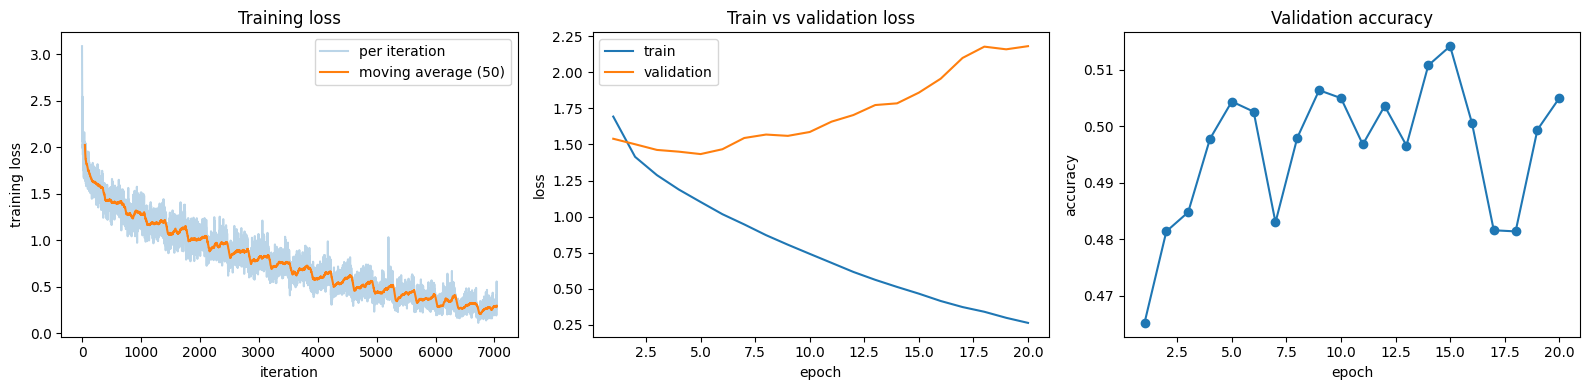

Final validation accuracy: 50.50%   (best: 51.42% at epoch 15)
Final train loss 0.263  |  final val loss 2.181


In [ ]:
it = np.array(hist_c['iter_loss'])
k = 50
smooth = np.convolve(it, np.ones(k) / k, mode='valid')
ep_axis = np.arange(1, len(hist_c['train_loss']) + 1)

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].plot(it, alpha=0.3, label='per iteration')
ax[0].plot(np.arange(k - 1, len(it)), smooth, label=f'moving average ({k})')
ax[0].set_xlabel('iteration'); ax[0].set_ylabel('training loss'); ax[0].set_title('Training loss'); ax[0].legend()
ax[1].plot(ep_axis, hist_c['train_loss'], label='train'); ax[1].plot(ep_axis, hist_c['val_loss'], label='validation')
ax[1].set_xlabel('epoch'); ax[1].set_ylabel('loss'); ax[1].set_title('Train vs validation loss'); ax[1].legend()
ax[2].plot(ep_axis, hist_c['val_acc'], marker='o')
ax[2].set_xlabel('epoch'); ax[2].set_ylabel('accuracy'); ax[2].set_title('Validation accuracy')
plt.tight_layout(); savefig('task1c_training.png'); plt.show()

final_acc = hist_c['val_acc'][-1]
print(f'Final validation accuracy: {final_acc * 100:.2f}%   (best: {max(hist_c["val_acc"]) * 100:.2f}% at epoch {int(np.argmax(hist_c["val_acc"])) + 1})')
print(f'Final train loss {hist_c["train_loss"][-1]:.3f}  |  final val loss {hist_c["val_loss"][-1]:.3f}')

### Interpretation
#### Training loss
The loss starts high and falls quickly to about 1.7 within the first few hundred iterations. After that it declines steadily, reaching about 0.3 after 7,000 iterations.

#### Train vs validation loss

In epoch 1 the validation loss 1.54 is lower than the training loss 1.69.From epoch 2 the training loss keeps falling to 0.26, but the validation loss reaches its minimum around epoch 5 and then rises steadily to about 2.2.

#### Validation accuracy

Accuracy rises from 46.5% to about 50% in the first five epochs and then fluctuates between roughly 48% and 51% without a clear upward trend. The peak of 51.4% at epoch 15.

### 1) (d) For a 10-layer MLP, plot the per-layer gradient norm at initialization with sigmoid and with ReLU. Explain

Sigmoid + Xavier         init loss  2.509 | layer1 1.39e-05  layer5 1.31e-03  layer10 1.40e+00 | layer1/layer10 = 9.94e-06
ReLU + Kaiming           init loss  2.708 | layer1 3.00e+00  layer5 1.75e+00  layer10 3.07e+00 | layer1/layer10 = 9.78e-01
ReLU + Xavier (extra)    init loss  2.304 | layer1 1.40e-01  layer5 5.79e-02  layer10 3.61e-02 | layer1/layer10 = 3.87e+00


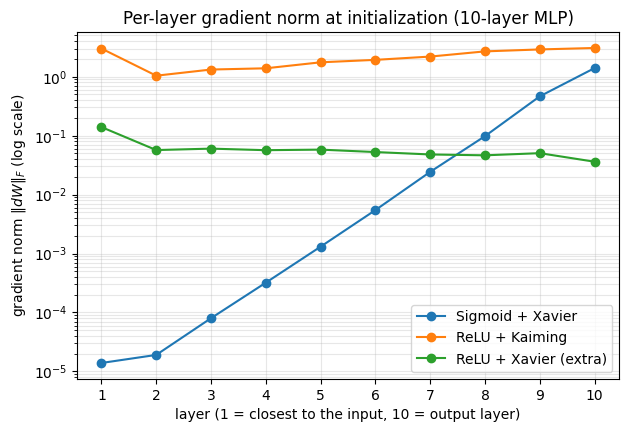

In [ ]:
def layer_grad_norms(act, init, depth=10, width=256, bs=512, seed=42):
    set_seed(seed)
    sizes = [3072] + [width] * (depth - 1) + [10]          # depth Linear layers in total
    net = MLP(sizes, act=act, init=init, device=device)
    xb, yb = X_train[:bs].flatten(1), y_train[:bs]
    loss = net.loss(xb, yb); net.backward()
    return [l.dW.norm().item() for l in net.linears()], loss.item()

configs = [('sigmoid', 'xavier', 'Sigmoid + Xavier'),
           ('relu',    'kaiming', 'ReLU + Kaiming'),
           ('relu',    'xavier',  'ReLU + Xavier (extra)')]
norms = {}
for act, init, label in configs:
    norms[label], l0 = layer_grad_norms(act, init)
    n = norms[label]
    print(f'{label:24s} init loss {l0:6.3f} | layer1 {n[0]:.2e}  layer5 {n[4]:.2e}  layer10 {n[-1]:.2e} | layer1/layer10 = {n[0] / n[-1]:.2e}')

save_result('task1d_gradnorms', norms)             # kept on Drive for the report

layers = np.arange(1, 11)
plt.figure(figsize=(7, 4.5))
for label, n in norms.items():
    plt.semilogy(layers, n, marker='o', label=label)
plt.xlabel('layer (1 = closest to the input, 10 = output layer)')
plt.ylabel(r'gradient norm $\|dW\|_F$ (log scale)')
plt.title('Per-layer gradient norm at initialization (10-layer MLP)')
plt.xticks(layers); plt.grid(alpha=0.3, which='both'); plt.legend()
savefig('task1d_grad_norms.png'); plt.show()

### Interpretation
The gradient norm shrinks steadily from the output layer to the input in Sigmoid + Xavier initialization. It is 1.4 at layer 10 and 1.4e-5 at layer. This shows clear signs of vanishing gradient problem. Therefore the layer at the begining learns barely. On the other hand with ReLU + Kaiming initialization the gradient norm remains approximately same so no vanishing gradient problem will occur. With ReLU + Xavier initialization the initialized weight may be small and so forward path output shrinks and gradients may become small in the begining resulting slow learning.

## Task 02

### 2) (a) Implement SGD with momentum and Adam (with bias correction) as torch.optim.Optimizer subclasses. Show that they match torch.optim.SGD and torch.optim.Adam.

In [ ]:
from torch.optim import Optimizer
class SGDMomentum(Optimizer):
    def __init__(self, params, lr=0.01, momentum=0.9, weight_decay=0.0):
        if lr < 0: raise ValueError('lr must be >= 0')
        super().__init__(params, dict(lr=lr, momentum=momentum, weight_decay=weight_decay))

    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad():
                loss = closure()
        for group in self.param_groups:
            lr, mu, wd = group['lr'], group['momentum'], group['weight_decay']
            for p in group['params']:
                if p.grad is None:
                    continue
                g = p.grad
                if wd != 0:
                    g = g.add(p, alpha=wd)                      # L2 penalty
                state = self.state[p]
                if 'buf' not in state:
                    state['buf'] = g.clone()                    # first step: buf = g
                else:
                    state['buf'].mul_(mu).add_(g)               # buf = mu*buf + g
                p.add_(state['buf'], alpha=-lr)                 # theta -= lr*buf
        return loss


class Adam(Optimizer):
    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8, weight_decay=0.0):
        if lr < 0: raise ValueError('lr must be >= 0')
        super().__init__(params, dict(lr=lr, betas=betas, eps=eps, weight_decay=weight_decay))

    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad():
                loss = closure()
        for group in self.param_groups:
            lr, (b1, b2), eps, wd = group['lr'], group['betas'], group['eps'], group['weight_decay']
            for p in group['params']:
                if p.grad is None:
                    continue
                g = p.grad
                if wd != 0:
                    g = g.add(p, alpha=wd)
                state = self.state[p]
                if len(state) == 0:
                    state['t'] = 0
                    state['m'] = torch.zeros_like(p)
                    state['v'] = torch.zeros_like(p)
                state['t'] += 1
                t = state['t']
                state['m'].mul_(b1).add_(g, alpha=1 - b1)              # first moment
                state['v'].mul_(b2).addcmul_(g, g, value=1 - b2)       # second moment
                m_hat = state['m'] / (1 - b1 ** t)                     # bias correction
                v_hat = state['v'] / (1 - b2 ** t)
                p.addcdiv_(m_hat, v_hat.sqrt().add_(eps), value=-lr)   # theta -= lr * m_hat / (sqrt(v_hat) + eps)
        return loss

print('SGDMomentum and Adam defined.')

SGDMomentum and Adam defined.


In [ ]:
def make_small(seed=0):
    torch.manual_seed(seed)
    return nn.Sequential(nn.Linear(10, 16), nn.Tanh(), nn.Linear(16, 3)).double()

def compare_opts(mine_cls, mine_kw, ref_cls, ref_kw, steps=50, seed=0):
    torch.manual_seed(seed + 1)
    X = torch.randn(64, 10, dtype=torch.float64)
    y = torch.randint(0, 3, (64,))
    a, b = make_small(seed), make_small(seed)
    oa, ob = mine_cls(a.parameters(), **mine_kw), ref_cls(b.parameters(), **ref_kw)
    max_diff, loss_diff = 0.0, 0.0
    for _ in range(steps):
        for net, opt in ((a, oa), (b, ob)):
            opt.zero_grad()
            F.cross_entropy(net(X), y).backward()
            opt.step()
        max_diff = max(max_diff, max((pa - pb).abs().max().item() for pa, pb in zip(a.parameters(), b.parameters())))
    ok = all(torch.allclose(pa, pb, rtol=1e-8, atol=1e-10) for pa, pb in zip(a.parameters(), b.parameters()))
    la, lb = F.cross_entropy(a(X), y).item(), F.cross_entropy(b(X), y).item()
    return max_diff, ok, la, lb

tests = [
    ('SGD (momentum=0)',          SGDMomentum, dict(lr=0.1, momentum=0.0),                    torch.optim.SGD,  dict(lr=0.1)),
    ('SGD momentum 0.9',          SGDMomentum, dict(lr=0.05, momentum=0.9),                   torch.optim.SGD,  dict(lr=0.05, momentum=0.9)),
    ('SGD momentum 0.9 + wd',     SGDMomentum, dict(lr=0.05, momentum=0.9, weight_decay=1e-2), torch.optim.SGD,  dict(lr=0.05, momentum=0.9, weight_decay=1e-2)),
    ('Adam',                      Adam,        dict(lr=1e-2),                                 torch.optim.Adam, dict(lr=1e-2)),
    ('Adam + wd',                 Adam,        dict(lr=1e-2, weight_decay=1e-2),              torch.optim.Adam, dict(lr=1e-2, weight_decay=1e-2)),
]
print(f'{"optimizer":26s} {"max |param diff|":>17s} {"allclose":>9s} {"final loss (ours)":>18s} {"final loss (torch)":>19s}')
for name, mc, mk, rc, rk in tests:
    d, ok, la, lb = compare_opts(mc, mk, rc, rk)
    print(f'{name:26s} {d:17.2e} {str(ok):>9s} {la:18.10f} {lb:19.10f}')

optimizer                   max |param diff|  allclose  final loss (ours)  final loss (torch)
SGD (momentum=0)                    0.00e+00      True       0.9564413725        0.9564413725
SGD momentum 0.9                    0.00e+00      True       0.7944567235        0.7944567235
SGD momentum 0.9 + wd               0.00e+00      True       0.8280842083        0.8280842083
Adam                                1.03e-15      True       0.5500556636        0.5500556636
Adam + wd                           6.11e-16      True       0.6044956555        0.6044956555


#### Interpretation
According to the above results the above implemented SGDMomentum and Adam optimizers results the same results from **torch.optim.Adam** and **torch.optim.SGD** for all five tests. Also torch.allclose also resulted True in every case. This shows our implementation is very close(accurate) to the implementation in PyTorch.

2) (b)

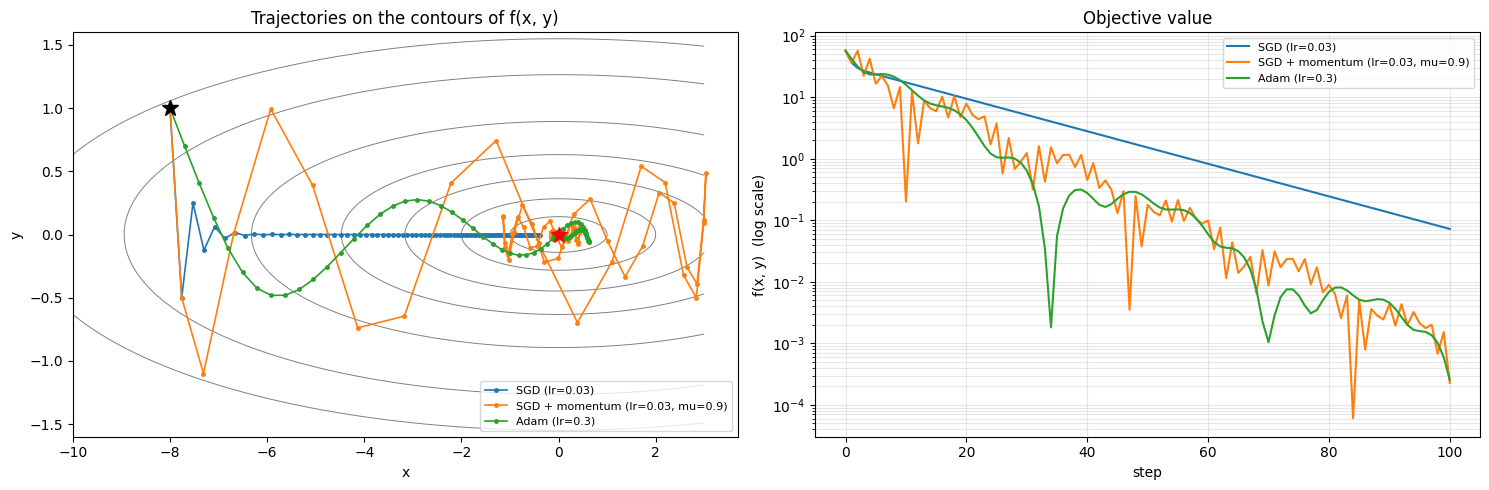

optimizer                             f after 100 steps   first step with f<1e-3    max |y| after step 5
SGD (lr=0.03)                                  7.24e-02              not reached                    0.03
SGD + momentum (lr=0.03, mu=0.9)               2.27e-04                       84                    0.74
Adam (lr=0.3)                                  2.56e-04                       99                    0.48


In [ ]:
def f2d(p):  return 0.5 * (p[0] ** 2 + 50.0 * p[1] ** 2)

def run_2d(opt_cls, steps, start, **kw):
    p = torch.tensor(start, dtype=torch.float64, requires_grad=True)
    opt = opt_cls([p], **kw)
    path = [p.detach().numpy().copy()]
    for _ in range(steps):
        opt.zero_grad()
        f2d(p).backward()
        opt.step()
        path.append(p.detach().numpy().copy())
    return np.array(path)

start, STEPS = [-8.0, 1.0], 100
paths = {
    'SGD (lr=0.03)':                run_2d(SGDMomentum, STEPS, start, lr=0.03, momentum=0.0),
    'SGD + momentum (lr=0.03, mu=0.9)': run_2d(SGDMomentum, STEPS, start, lr=0.03, momentum=0.9),
    'Adam (lr=0.3)':                run_2d(Adam, STEPS, start, lr=0.3),
}
fvals = {k: 0.5 * (v[:, 0] ** 2 + 50 * v[:, 1] ** 2) for k, v in paths.items()}

xs, ys = np.linspace(-10, 3, 400), np.linspace(-1.6, 1.6, 400)
XX, YY = np.meshgrid(xs, ys)
ZZ = 0.5 * (XX ** 2 + 50 * YY ** 2)

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
ax[0].contour(XX, YY, ZZ, levels=[0.5, 2, 5, 10, 20, 40, 60], colors='gray', linewidths=0.7)
for (name, path), c in zip(paths.items(), ['tab:blue', 'tab:orange', 'tab:green']):
    ax[0].plot(path[:, 0], path[:, 1], '-o', ms=2.5, lw=1.2, color=c, label=name)
ax[0].plot(*start, 'k*', ms=12); ax[0].plot(0, 0, 'r*', ms=12)
ax[0].set_xlabel('x'); ax[0].set_ylabel('y'); ax[0].set_title('Trajectories on the contours of f(x, y)'); ax[0].legend(loc='lower right', fontsize=8)
for (name, fv), c in zip(fvals.items(), ['tab:blue', 'tab:orange', 'tab:green']):
    ax[1].semilogy(fv + 1e-12, color=c, label=name)
ax[1].set_xlabel('step'); ax[1].set_ylabel('f(x, y)  (log scale)'); ax[1].set_title('Objective value'); ax[1].grid(alpha=0.3, which='both'); ax[1].legend(fontsize=8)
plt.tight_layout(); savefig('task2b_trajectories.png'); plt.show()

print(f'{"optimizer":36s} {"f after 100 steps":>18s} {"first step with f<1e-3":>24s}  {"max |y| after step 5":>22s}')
for name, path in paths.items():
    fv = fvals[name]
    hit = int(np.argmax(fv < 1e-3)) if (fv < 1e-3).any() else 'not reached'
    print(f'{name:36s} {fv[-1]:18.2e} {str(hit):>24s}  {np.abs(path[5:, 1]).max():22.2f}')

### Interpretation
In the contour plots the curvature(gradient) along y is 50 times the curvature along x due to the difference in coefficients. In **SGD** due to higher gradient y value reaches it's minimum faster compared to x. After that x value takes larger number of steps to reach minimum. Even after 100 steps f value is 7.24e-02 far away from it's true minimum (0) which occurs at x = 0 and y = 0. y value has reached very closer to 0 but x reaches it's minimum very slowly.

In SGD with momentum builds up the speed along the valley but it results overshoot. Around 84th step it reaches the f < 1e-3 threshold and oscillates around the minimum and after 100 steps it reaches a value of 2.27e-04.

In Adam both x and y coordinates takes similar steps and reaches towards the minimum it also results overshoot and it's path is a smooth curve compared to SDG with momentum. It reaches a value of f below the threshold in a step arround 99 and after 100 steps it's value becomes 2.56e-04.

2) (C)

In [ ]:
def make_cnn():
    net = nn.Sequential(
        nn.Conv2d(3, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),     # 32 -> 16
        nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),    # 16 -> 8
        nn.Conv2d(64, 128, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),   # 8 -> 4
        nn.Flatten(), nn.Linear(128 * 4 * 4, 128), nn.ReLU(), nn.Linear(128, 10))
    for m in net:
        if isinstance(m, (nn.Conv2d, nn.Linear)):
            nn.init.kaiming_normal_(m.weight, nonlinearity='relu'); nn.init.zeros_(m.bias)
    return net

print('parameters:', sum(p.numel() for p in make_cnn().parameters()))

def mb_iter2(X, y, bs, seed):
    g = torch.Generator().manual_seed(seed)
    idx = torch.randperm(len(X), generator=g).to(X.device)
    for i in range(0, len(X), bs):
        j = idx[i:i + bs]
        yield X[j], y[j]

@torch.no_grad()
def eval_model(model, X, y, bs=1000):
    model.eval()
    tot, correct = 0.0, 0
    for i in range(0, len(X), bs):
        out = model(X[i:i + bs])
        tot += F.cross_entropy(out, y[i:i + bs], reduction='sum').item()
        correct += (out.argmax(1) == y[i:i + bs]).sum().item()
    model.train()
    return tot / len(X), correct / len(X)

def make_opt(name, params, lr):
    if name == 'SGD':          return SGDMomentum(params, lr=lr, momentum=0.0)
    if name == 'SGD+momentum': return SGDMomentum(params, lr=lr, momentum=0.9)
    if name == 'Adam':         return Adam(params, lr=lr)
    raise ValueError(name)

def train_cnn(opt_name, lr, epochs=15, bs=128, seed=42):
    set_seed(seed)
    model = make_cnn().to(device)
    opt = make_opt(opt_name, model.parameters(), lr)
    h = {'iter_loss': [], 'train_loss': [], 'val_loss': [], 'val_acc': [], 'diverged': False}
    for ep in range(epochs):
        losses = []
        for xb, yb in mb_iter2(X_train, y_train, bs, seed * 1000 + ep):
            opt.zero_grad()
            loss = F.cross_entropy(model(xb), yb)
            if not torch.isfinite(loss):
                h['diverged'] = True
                break
            loss.backward()
            opt.step()
            losses.append(loss.item())
        h['iter_loss'] += losses
        if h['diverged']:
            break
        vl, va = eval_model(model, X_val, y_val)
        h['train_loss'].append(float(np.mean(losses))); h['val_loss'].append(vl); h['val_acc'].append(va)
    return h

GRID = {'SGD':          [0.001, 0.01, 0.1],
        'SGD+momentum': [0.001, 0.01, 0.1],
        'Adam':         [1e-4, 1e-3, 1e-2]}
EPOCHS = 15
RERUN = False       # True = ignore saved results and retrain everything

runs = {}
t0 = time.time()
for opt_name, lrs in GRID.items():
    for lr in lrs:
        key = f'task2c_{opt_name}_{lr:g}'
        if result_exists(key) and not RERUN:
            runs[(opt_name, lr)] = load_result(key); tag = 'loaded'
        else:
            runs[(opt_name, lr)] = train_cnn(opt_name, lr, epochs=EPOCHS); save_result(key, runs[(opt_name, lr)]); tag = 'trained'
        h = runs[(opt_name, lr)]
        status = 'DIVERGED (loss became NaN/inf)' if h['diverged'] else f'final val acc {h["val_acc"][-1]:.4f} | final train loss {h["train_loss"][-1]:.3f}'
        print(f'[{tag:7s}] {opt_name:13s} lr={lr:<7g} {status}')
print(f'total time {time.time() - t0:.0f}s')

parameters: 356810
[trained] SGD           lr=0.001   final val acc 0.5248 | final train loss 1.317
[trained] SGD           lr=0.01    final val acc 0.6726 | final train loss 0.762
[trained] SGD           lr=0.1     final val acc 0.6912 | final train loss 0.197
[trained] SGD+momentum  lr=0.001   final val acc 0.6738 | final train loss 0.740
[trained] SGD+momentum  lr=0.01    final val acc 0.7294 | final train loss 0.169
[trained] SGD+momentum  lr=0.1     final val acc 0.5594 | final train loss 1.237
[trained] Adam          lr=0.0001  final val acc 0.6598 | final train loss 0.716
[trained] Adam          lr=0.001   final val acc 0.7184 | final train loss 0.135
[trained] Adam          lr=0.01    final val acc 0.4908 | final train loss 1.351
total time 311s


### Interpretation
Trained a small CNN with the optimizers SGD, SGD with momentum with different learning rate 0.001, 0.01 and 0.1. And with Adam the learning rates used are 0.0001,0.001 and 0.01.

optimizer            lr  final val acc  best val acc  final train loss  status
SGD               0.001         0.5248        0.5248            1.3171  ok
SGD                0.01         0.6726        0.6726            0.7618  ok
SGD                 0.1         0.6912        0.7190            0.1969  ok
SGD+momentum      0.001         0.6738        0.6770            0.7397  ok
SGD+momentum       0.01         0.7294        0.7294            0.1690  ok
SGD+momentum        0.1         0.5594        0.5594            1.2374  ok
Adam             0.0001         0.6598        0.6662            0.7162  ok
Adam              0.001         0.7184        0.7284            0.1352  ok
Adam               0.01         0.4908        0.4914            1.3512  ok

best learning rate (by final validation accuracy): {'SGD': 0.1, 'SGD+momentum': 0.01, 'Adam': 0.001}


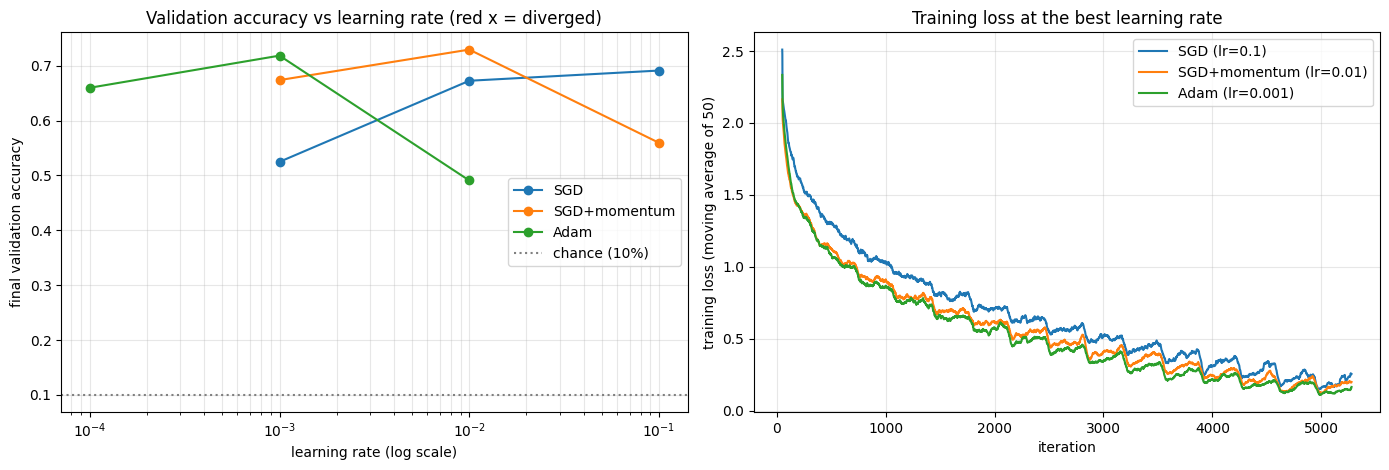

In [ ]:
CHANCE = 0.10
def final_acc(h):  return CHANCE if h['diverged'] or len(h['val_acc']) == 0 else h['val_acc'][-1]

print(f'{"optimizer":14s} {"lr":>8s} {"final val acc":>14s} {"best val acc":>13s} {"final train loss":>17s}  status')
best = {}
for opt_name, lrs in GRID.items():
    for lr in lrs:
        h = runs[(opt_name, lr)]
        if h['diverged']:
            print(f'{opt_name:14s} {lr:8g} {"-":>14s} {"-":>13s} {"-":>17s}  diverged')
        else:
            print(f'{opt_name:14s} {lr:8g} {h["val_acc"][-1]:14.4f} {max(h["val_acc"]):13.4f} {h["train_loss"][-1]:17.4f}  ok')
    best[opt_name] = max(lrs, key=lambda lr: final_acc(runs[(opt_name, lr)]))
print('\nbest learning rate (by final validation accuracy):', best)

colors = {'SGD': 'tab:blue', 'SGD+momentum': 'tab:orange', 'Adam': 'tab:green'}
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
for opt_name, lrs in GRID.items():
    accs = [final_acc(runs[(opt_name, lr)]) for lr in lrs]
    ax[0].semilogx(lrs, accs, '-o', color=colors[opt_name], label=opt_name)
    for lr, a in zip(lrs, accs):
        if runs[(opt_name, lr)]['diverged']:
            ax[0].plot(lr, a, 'x', ms=12, mew=2, color='red')
ax[0].axhline(CHANCE, color='gray', ls=':', label='chance (10%)')
ax[0].set_xlabel('learning rate (log scale)'); ax[0].set_ylabel('final validation accuracy')
ax[0].set_title('Validation accuracy vs learning rate (red x = diverged)'); ax[0].grid(alpha=0.3, which='both'); ax[0].legend()

k = 50
for opt_name in GRID:
    h = runs[(opt_name, best[opt_name])]
    it = np.array(h['iter_loss'])
    ax[1].plot(np.arange(k - 1, len(it)), np.convolve(it, np.ones(k) / k, mode='valid'), color=colors[opt_name],
               label=f'{opt_name} (lr={best[opt_name]:g})')
ax[1].set_xlabel('iteration'); ax[1].set_ylabel('training loss (moving average of 50)')
ax[1].set_title('Training loss at the best learning rate'); ax[1].grid(alpha=0.3); ax[1].legend()
plt.tight_layout(); savefig('task2c_lr_sensitivity.png'); plt.show()

### Interpretation

From the final validation accuracy vs learning rate plot, the best learning rate for SGD is 0.1 which results an accuracy of 69%, for SGD with momentum the best learning rate is 0.01 which results an accuracy of 73% and for Adam, the best learning rate is 0.001 which results an accuracy of 72%. The validation accuracy increases for SDG when learning rate increased from 0.001 to 0.1. Smaller learning rates has resulted slowness in learning process as at the end of the 15 epoches training loss decreases with increasing learning rate.

For SGD with momentum, a higher validation accuracy(73%) and low training loss(0.1690) is resulted for the learning rate 0.01. It is more sensitive to large learning rate(0.1) (final validation accuracy: 56%, final training loss: 1.2374) compared to very small learning rate (0.001) (final validation accuracy: 67%, final training loss: 0.7397). So a balanced learning rate is prefered.

For Adam, a higher validation accuracy(72%) and low training loss(0.1352) is resulted for the learning rate 0.001. It is more sensitive to large learning rate(0.01) (final validation accuracy: 49%, final training loss: 1.3512) compared to very small learning rate (0.0001) (final validation accuracy: 66%, final training loss: 0.7162). So a balanced learning rate is prefered.


## Task 3

3) (a)

In [ ]:
def aug_flip_crop(x, pad=4):
    B = x.size(0)
    flip = torch.rand(B, device=x.device) < 0.5
    x = torch.where(flip[:, None, None, None], x.flip(3), x)
    xp = F.pad(x, (pad, pad, pad, pad))                               # zero padding
    i = torch.randint(0, 2 * pad + 1, (B,), device=x.device)
    j = torch.randint(0, 2 * pad + 1, (B,), device=x.device)
    ar = torch.arange(32, device=x.device)
    rows = (i[:, None] + ar)[:, None, :, None]                        # B,1,32,1
    cols = (j[:, None] + ar)[:, None, None, :]                        # B,1,1,32
    bidx = torch.arange(B, device=x.device)[:, None, None, None]
    cidx = torch.arange(3, device=x.device)[None, :, None, None]
    return xp[bidx, cidx, rows, cols]                                 # B,3,32,32

def cutout(x, size=16):
    B, _, H, W = x.shape
    cy = torch.randint(0, H, (B,), device=x.device)
    cx = torch.randint(0, W, (B,), device=x.device)
    ys = torch.arange(H, device=x.device)[None, :, None]
    xs = torch.arange(W, device=x.device)[None, None, :]
    h = size // 2
    m = ((ys >= (cy - h)[:, None, None]) & (ys < (cy + h)[:, None, None]) &
         (xs >= (cx - h)[:, None, None]) & (xs < (cx + h)[:, None, None]))
    return x * (~m)[:, None, :, :].to(x.dtype)

def mixup(x, y, alpha=0.4):
    B = x.size(0)
    lam = torch.distributions.Beta(alpha, alpha).sample((B,)).to(x.device)
    perm = torch.randperm(B, device=x.device)
    xm = lam[:, None, None, None] * x + (1 - lam)[:, None, None, None] * x[perm]
    return xm, y, y[perm], lam

def mixup_loss(out, ya, yb, lam):
    return (lam * F.cross_entropy(out, ya, reduction='none') + (1 - lam) * F.cross_entropy(out, yb, reduction='none')).mean()

def batches3(X, y, bs, seed, drop_last=True):
    g = torch.Generator().manual_seed(seed)
    idx = torch.randperm(len(X), generator=g).to(X.device)
    n = len(X) - (len(X) % bs if drop_last else 0)
    for i in range(0, n, bs):
        j = idx[i:i + bs]
        yield X[j], y[j]

@torch.no_grad()
def eval3(model, X, y, bs=1000):
    model.eval()
    tot, correct = 0.0, 0
    for i in range(0, len(X), bs):
        out = model(X[i:i + bs])
        tot += F.cross_entropy(out, y[i:i + bs], reduction='sum').item()
        correct += (out.argmax(1) == y[i:i + bs]).sum().item()
    return tot / len(X), correct / len(X)

In [ ]:
import math
# fixed class-balanced 5k subset of the training split
g = torch.Generator().manual_seed(SEED)
ytr_cpu = y_train.cpu()
sub = torch.cat([(ytr_cpu == c).nonzero().flatten()[torch.randperm(int((ytr_cpu == c).sum()), generator=g)[:500]] for c in range(10)])
X5, y5 = X_train[sub.to(device)], y_train[sub.to(device)]
print('5k subset:', tuple(X5.shape), '| per-class counts:', torch.bincount(y5).tolist())

def conv_bn(cin, cout):
    return [nn.Conv2d(cin, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True)]

def make_reg_cnn(dropout=0.0):
    layers, cin = [], 3
    for cout in (32, 64, 128):
        layers += conv_bn(cin, cout) + conv_bn(cout, cout) + [nn.MaxPool2d(2)]
        if dropout > 0: layers.append(nn.Dropout(dropout))
        cin = cout
    layers += [nn.AdaptiveAvgPool2d(1), nn.Flatten()]
    if dropout > 0: layers.append(nn.Dropout(dropout))
    layers.append(nn.Linear(128, 10))
    net = nn.Sequential(*layers)
    for m in net.modules():
        if isinstance(m, nn.Conv2d): nn.init.kaiming_normal_(m.weight, nonlinearity='relu')
    return net

print('parameters:', sum(p.numel() for p in make_reg_cnn().parameters()))

def train_reg(cfg, epochs=60, bs=128, lr=0.05, seed=42):
    set_seed(seed)
    model = make_reg_cnn(cfg.get('dropout', 0.0)).to(device)
    opt = SGDMomentum(model.parameters(), lr=lr, momentum=0.9, weight_decay=cfg.get('wd', 0.0))
    h = {k: [] for k in ('train_loss', 'train_acc', 'val_loss', 'val_acc', 'batch_loss')}
    for ep in range(epochs):
        for gr in opt.param_groups:
            gr['lr'] = lr * 0.5 * (1 + math.cos(math.pi * ep / epochs))        # cosine decay per epoch
        model.train()
        bl = []
        for xb, yb in batches3(X5, y5, bs, seed * 1000 + ep):
            if cfg.get('flipcrop'): xb = aug_flip_crop(xb)
            if cfg.get('cutout'):   xb = cutout(xb)
            opt.zero_grad()
            if cfg.get('mixup'):
                xb, ya, yb2, lam = mixup(xb, yb, alpha=0.4)
                loss = mixup_loss(model(xb), ya, yb2, lam)
            else:
                loss = F.cross_entropy(model(xb), yb)
            loss.backward(); opt.step(); bl.append(loss.item())
        h['batch_loss'].append(float(np.mean(bl)))
        tl, ta = eval3(model, X5, y5); vl, va = eval3(model, X_val, y_val)
        h['train_loss'].append(tl); h['train_acc'].append(ta); h['val_loss'].append(vl); h['val_acc'].append(va)
    return h

CONFIGS = {
    'baseline':     {},
    'weight decay': dict(wd=5e-4),
    'dropout':      dict(dropout=0.3),
    'flip+crop':    dict(flipcrop=True),
    'cutout':       dict(cutout=True),
    'mixup':        dict(mixup=True),
    'all combined': dict(wd=5e-4, dropout=0.3, flipcrop=True, cutout=True, mixup=True),
}
EPOCHS_A = 60
RERUN_A = False        # True = ignore saved results and retrain

res_a = {}
t0 = time.time()
for name, cfg in CONFIGS.items():
    key = 'task3a_' + name.replace(' ', '_').replace('+', '_')
    if result_exists(key) and not RERUN_A:
        res_a[name] = load_result(key); tag = 'loaded '
    else:
        res_a[name] = train_reg(cfg, epochs=EPOCHS_A); save_result(key, res_a[name]); tag = 'trained'
    h = res_a[name]
    print(f'[{tag}] {name:13s} train acc {h["train_acc"][-1]:.4f} | val acc {h["val_acc"][-1]:.4f} | gap {h["train_acc"][-1] - h["val_acc"][-1]:+.4f}')
print(f'total time {time.time() - t0:.0f}s')

5k subset: (5000, 3, 32, 32) | per-class counts: [500, 500, 500, 500, 500, 500, 500, 500, 500, 500]
parameters: 288746
[trained] baseline      train acc 1.0000 | val acc 0.6806 | gap +0.3194
[trained] weight decay  train acc 1.0000 | val acc 0.6826 | gap +0.3174
[trained] dropout       train acc 0.9086 | val acc 0.6878 | gap +0.2208
[trained] flip+crop     train acc 0.9712 | val acc 0.7324 | gap +0.2388
[trained] cutout        train acc 1.0000 | val acc 0.7118 | gap +0.2882
[trained] mixup         train acc 1.0000 | val acc 0.6868 | gap +0.3132
[trained] all combined  train acc 0.6656 | val acc 0.6200 | gap +0.0456
total time 578s


configuration   train acc   val acc  gap (train-val)  best val acc  final val loss
----------------------------------------------------------------------------------
baseline          100.00%    68.06%           31.94%        68.42%           1.391
weight decay      100.00%    68.26%           31.74%        68.74%           1.187
dropout            90.86%    68.78%           22.08%        68.92%           0.939
flip+crop          97.12%    73.24%           23.88%        73.36%           0.885
cutout            100.00%    71.18%           28.82%        71.18%           1.181
mixup             100.00%    68.68%           31.32%        68.70%           0.958
all combined       66.56%    62.00%            4.56%        62.78%           1.073
(accuracies at the final epoch; train accuracy is measured on the clean 5k training images)


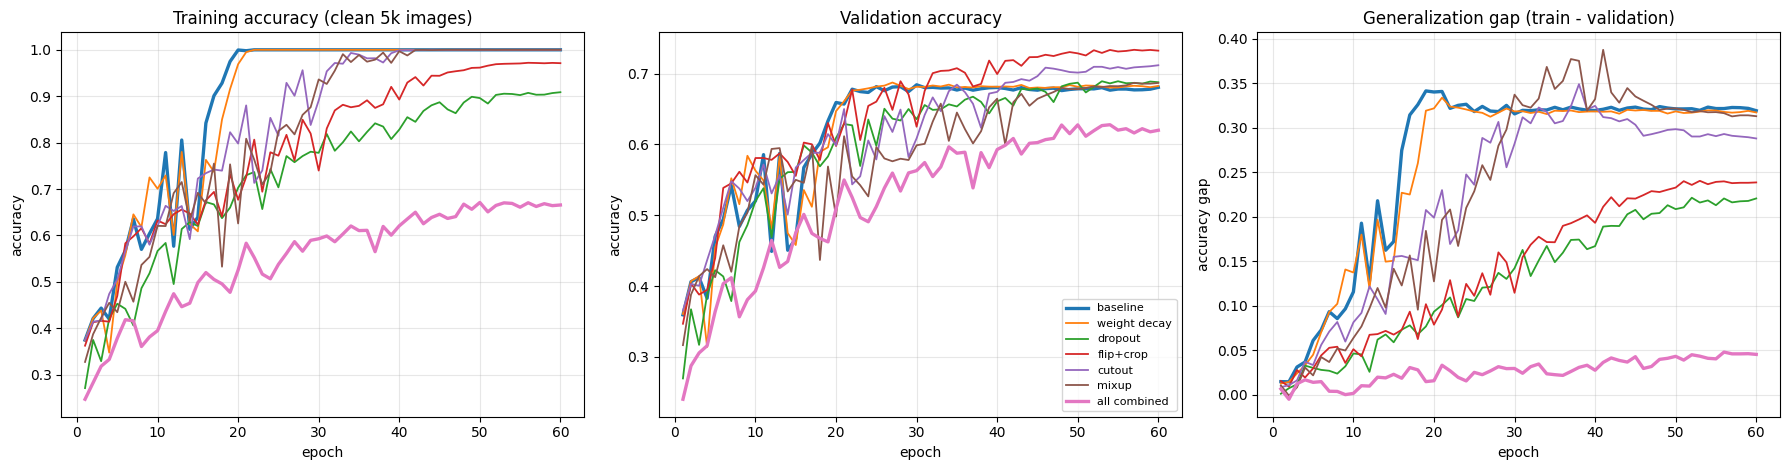

In [ ]:
print(f'{"configuration":14s} {"train acc":>10s} {"val acc":>9s} {"gap (train-val)":>16s} {"best val acc":>13s} {"final val loss":>15s}')
print('-' * 82)
for name, h in res_a.items():
    ta, va = h['train_acc'][-1], h['val_acc'][-1]
    print(f'{name:14s} {ta * 100:9.2f}% {va * 100:8.2f}% {(ta - va) * 100:15.2f}% {max(h["val_acc"]) * 100:12.2f}% {h["val_loss"][-1]:15.3f}')
print('(accuracies at the final epoch; train accuracy is measured on the clean 5k training images)')

fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))
ep = np.arange(1, EPOCHS_A + 1)
for name, h in res_a.items():
    lw = 2.4 if name in ('baseline', 'all combined') else 1.3
    ax[0].plot(ep, h['train_acc'], lw=lw, label=name)
    ax[1].plot(ep, h['val_acc'], lw=lw, label=name)
    ax[2].plot(ep, np.array(h['train_acc']) - np.array(h['val_acc']), lw=lw, label=name)
ax[0].set_title('Training accuracy (clean 5k images)'); ax[1].set_title('Validation accuracy'); ax[2].set_title('Generalization gap (train - validation)')
for a_ in ax: a_.set_xlabel('epoch'); a_.grid(alpha=0.3)
ax[0].set_ylabel('accuracy'); ax[1].set_ylabel('accuracy'); ax[2].set_ylabel('accuracy gap'); ax[1].legend(fontsize=8)
plt.tight_layout(); savefig('task3a_curves.png'); plt.show()

3) (b)

In [ ]:
class Block(nn.Module):
    def __init__(self, cin, cout, stride, residual):
        super().__init__()
        self.residual, self.stride, self.pad = residual, stride, (cout - cin) // 2
        self.conv1 = nn.Conv2d(cin, cout, 3, stride, 1, bias=False); self.bn1 = nn.BatchNorm2d(cout)
        self.conv2 = nn.Conv2d(cout, cout, 3, 1, 1, bias=False);     self.bn2 = nn.BatchNorm2d(cout)

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        if self.residual:
            sc = x
            if self.stride != 1 or self.pad > 0:                     # parameter-free shortcut (option A)
                sc = F.pad(x[:, :, ::self.stride, ::self.stride], (0, 0, 0, 0, self.pad, self.pad))
            out = out + sc
        return F.relu(out)

class CifarNet(nn.Module):
    def __init__(self, n, residual):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 16, 3, 1, 1, bias=False); self.bn1 = nn.BatchNorm2d(16)
        blocks, cin = [], 16
        for cout, stride in ((16, 1), (32, 2), (64, 2)):
            for b in range(n):
                blocks.append(Block(cin, cout, stride if b == 0 else 1, residual)); cin = cout
        self.blocks = nn.Sequential(*blocks)
        self.fc = nn.Linear(64, 10)
        for m in self.modules():
            if isinstance(m, (nn.Conv2d, nn.Linear)):
                nn.init.kaiming_normal_(m.weight, nonlinearity='relu')
                if getattr(m, 'bias', None) is not None: nn.init.zeros_(m.bias)

    def forward(self, x):
        x = F.relu(self.bn1(self.conv1(x)))
        x = self.blocks(x)
        return self.fc(F.adaptive_avg_pool2d(x, 1).flatten(1))

# sanity: depth = 6n+2 and both families have identical parameter counts
for d in (8, 20, 56):
    n = (d - 2) // 6
    pp, pr = (sum(p.numel() for p in CifarNet(n, r).parameters()) for r in (False, True))
    n_conv_fc = sum(isinstance(m, (nn.Conv2d, nn.Linear)) for m in CifarNet(n, True).modules())
    print(f'depth {d:2d}: n={n} | weight layers (conv+fc, excluding shortcuts) = {n_conv_fc} | params plain {pp:,} = residual {pr:,}: {pp == pr}')

depth  8: n=1 | weight layers (conv+fc, excluding shortcuts) = 8 | params plain 75,290 = residual 75,290: True
depth 20: n=3 | weight layers (conv+fc, excluding shortcuts) = 20 | params plain 269,722 = residual 269,722: True
depth 56: n=9 | weight layers (conv+fc, excluding shortcuts) = 56 | params plain 853,018 = residual 853,018: True


In [ ]:
def train_net(depth, residual, epochs=30, bs=128, lr_max=0.1, wd=1e-4, seed=42):
    set_seed(seed)
    model = CifarNet((depth - 2) // 6, residual).to(device)
    opt = SGDMomentum(model.parameters(), lr=lr_max, momentum=0.9, weight_decay=wd)
    spe = len(X_train) // bs                                   # iterations per epoch (drop_last)
    total, warm, t = epochs * spe, spe, 0
    h = {'train_loss': [], 'val_loss': [], 'val_acc': [], 'diverged': False, 'time': 0.0}
    t0 = time.time()
    for ep in range(epochs):
        model.train(); bl = []
        for xb, yb in batches3(X_train, y_train, bs, seed * 1000 + ep):
            lr = lr_max * (t + 1) / warm if t < warm else lr_max * 0.5 * (1 + math.cos(math.pi * (t - warm) / (total - warm)))
            for gr in opt.param_groups: gr['lr'] = lr
            opt.zero_grad()
            loss = F.cross_entropy(model(aug_flip_crop(xb)), yb)
            if not torch.isfinite(loss):
                h['diverged'] = True; break
            loss.backward(); opt.step(); bl.append(loss.item()); t += 1
        if h['diverged']: break
        vl, va = eval3(model, X_val, y_val)
        h['train_loss'].append(float(np.mean(bl))); h['val_loss'].append(vl); h['val_acc'].append(va)
        print(f'    epoch {ep + 1:2d}/{epochs} | train loss {h["train_loss"][-1]:.4f} | val loss {vl:.4f} | val acc {va:.4f} | {time.time() - t0:.0f}s elapsed')
    h['time'] = time.time() - t0
    return h

DEPTHS = [8, 20, 56]
EPOCHS_B = 20
RERUN_B = False

res_b = {}
for depth in DEPTHS:
    for residual in (False, True):
        fam = 'residual' if residual else 'plain'
        key = f'task3b_{fam}{depth}'
        if result_exists(key) and not RERUN_B:
            res_b[(fam, depth)] = load_result(key); tag = 'loaded '
        else:
            print(f'training {fam} depth {depth} ...')
            res_b[(fam, depth)] = train_net(depth, residual, epochs=EPOCHS_B); save_result(key, res_b[(fam, depth)]); tag = 'trained'
        h = res_b[(fam, depth)]
        if h['diverged']:
            print(f'[{tag}] {fam:8s} depth {depth:2d}: DIVERGED')
        else:
            print(f'[{tag}] {fam:8s} depth {depth:2d}: final train loss {h["train_loss"][-1]:.3f} | val acc {h["val_acc"][-1]:.4f} | {h["time"] / 60:.1f} min')

training plain depth 8 ...
    epoch  1/20 | train loss 1.7192 | val loss 1.8910 | val acc 0.3810 | 6s elapsed
    epoch  2/20 | train loss 1.2040 | val loss 1.4197 | val acc 0.5198 | 11s elapsed
    epoch  3/20 | train loss 1.0196 | val loss 1.5182 | val acc 0.5210 | 16s elapsed
    epoch  4/20 | train loss 0.9128 | val loss 0.9570 | val acc 0.6754 | 22s elapsed
    epoch  5/20 | train loss 0.8343 | val loss 0.8702 | val acc 0.6926 | 27s elapsed
    epoch  6/20 | train loss 0.7754 | val loss 0.7864 | val acc 0.7246 | 32s elapsed
    epoch  7/20 | train loss 0.7288 | val loss 0.7933 | val acc 0.7184 | 38s elapsed
    epoch  8/20 | train loss 0.6868 | val loss 0.7076 | val acc 0.7538 | 43s elapsed
    epoch  9/20 | train loss 0.6530 | val loss 0.8530 | val acc 0.7046 | 49s elapsed
    epoch 10/20 | train loss 0.6257 | val loss 0.6614 | val acc 0.7724 | 54s elapsed
    epoch 11/20 | train loss 0.5937 | val loss 0.6841 | val acc 0.7618 | 60s elapsed
    epoch 12/20 | train loss 0.5684 | v

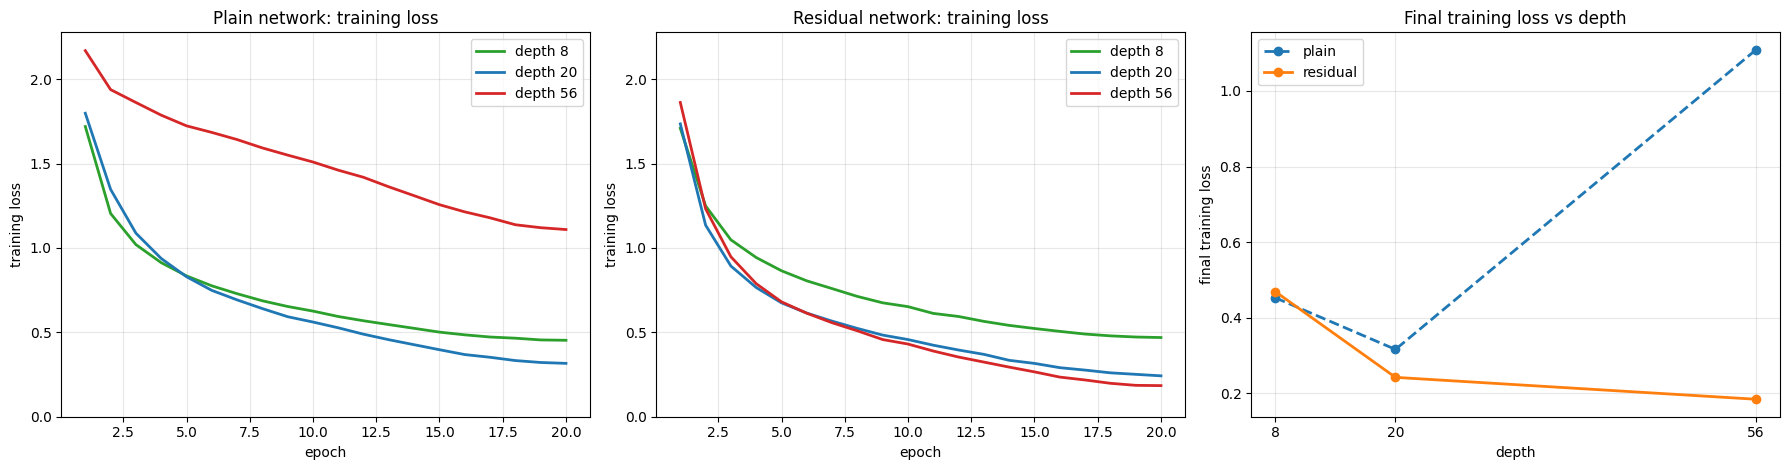

family    depth    params  final train loss  final val acc  time (min)
plain         8    75,290            0.4528         82.78%         1.8
residual      8    75,290            0.4691         82.36%         1.9
plain        20   269,722            0.3161         86.06%         4.5
residual     20   269,722            0.2422         88.12%         4.6
plain        56   853,018            1.1089         60.70%        12.5
residual     56   853,018            0.1843         88.70%        13.0


In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))
cols = {8: 'tab:green', 20: 'tab:blue', 56: 'tab:red'}
for fam, a_ in zip(('plain', 'residual'), ax[:2]):
    for d in DEPTHS:
        h = res_b[(fam, d)]
        a_.plot(np.arange(1, len(h['train_loss']) + 1), h['train_loss'], color=cols[d], lw=2, label=f'depth {d}')
    a_.set_title(f'{fam.capitalize()} network: training loss'); a_.set_xlabel('epoch'); a_.set_ylabel('training loss'); a_.grid(alpha=0.3); a_.legend()
ymax = max(max(res_b[k]['train_loss']) for k in res_b if res_b[k]['train_loss']) * 1.05
ax[0].set_ylim(0, ymax); ax[1].set_ylim(0, ymax)
for fam, ls in (('plain', '--'), ('residual', '-')):
    ax[2].plot(DEPTHS, [res_b[(fam, d)]['train_loss'][-1] for d in DEPTHS], ls, marker='o', lw=2, label=fam)
ax[2].set_xticks(DEPTHS); ax[2].set_xlabel('depth'); ax[2].set_ylabel('final training loss'); ax[2].set_title('Final training loss vs depth')
ax[2].grid(alpha=0.3); ax[2].legend()
plt.tight_layout(); savefig('task3b_training_loss.png'); plt.show()

print(f'{"family":9s} {"depth":>5s} {"params":>9s} {"final train loss":>17s} {"final val acc":>14s} {"time (min)":>11s}')
for d in DEPTHS:
    for fam in ('plain', 'residual'):
        h = res_b[(fam, d)]
        npar = sum(p.numel() for p in CifarNet((d - 2) // 6, fam == 'residual').parameters())
        if h['diverged']: print(f'{fam:9s} {d:5d} {npar:9,d} {"diverged":>17s}')
        else: print(f'{fam:9s} {d:5d} {npar:9,d} {h["train_loss"][-1]:17.4f} {h["val_acc"][-1] * 100:13.2f}% {h["time"] / 60:11.1f}')